# 04 — Hospital Readmission Classification: logistic regression vs a decision tree

**TL;DR.** I predict **30-day readmission** for diabetic hospital encounters using the UCI
"Diabetes 130-US Hospitals" dataset. After excluding hospice/expired discharges and splitting by
patient (not by row), the positive rate is **11.4%**. A plain logistic regression gets **88.8%
accuracy but catches only 2.5% of readmissions** — the accuracy paradox in one line. Re-weighting the
classes lifts recall to **54.3%** at **18.2% precision** (F1 0.273, ROC-AUC 0.667), and a depth-5
decision tree lands in the same place (recall 56.6%, F1 0.268). Prior inpatient visits are the
strongest signal. The honest conclusion: readmission is predictable only weakly from administrative
data, and the threshold should be chosen from the cost of a missed patient versus a false alarm, not
from accuracy.

*Portfolio project 04 of 07 · classification, class imbalance, leakage-aware splitting, metrics.*

## 1. What this notebook does

This is a binary classification project with a deliberately awkward target. It covers:

1. **Defining the label** — 30-day readmission, and why the three-level `readmitted` column has to be
   collapsed carefully.
2. **Leakage-aware splitting** — the same patient appears in multiple encounters; a random row split
   would leak information.
3. **Class imbalance** — 11% positives is not extreme, but it is enough to make accuracy useless.
4. **Two model families** — logistic regression (linear, interpretable) and a decision tree
   (non-linear, rule-based).
5. **Threshold selection** — the default 0.5 is a choice, and usually the wrong one for a clinical
   screening task.

The notebook is written for a reader who knows the basics of supervised learning but wants to see
how the methodological decisions are made.

## 2. The problem, and why it matters

Hospitals are penalised for excess readmissions, and care teams have limited capacity for follow-up
calls, home visits, and medication reviews. A model that ranks patients by readmission risk can help
allocate that capacity. The value is not in a perfect prediction; it is in moving a small number of
high-risk patients to the front of the queue.

The dataset is a classic benchmark: 101,766 encounters from 130 US hospitals between 1999 and 2008,
with demographics, admission details, diagnoses, medications, and lab results. The target
`readmitted` has three values:

- `NO` — not readmitted
- `>30` — readmitted after 30 days
- `<30` — readmitted within 30 days

I model `<30` as the positive class because 30 days is the window most hospital programmes are
accountable for. `>30` is treated as a negative, which is a simplification: a patient readmitted on
day 45 is not the same as one who was never readmitted. I discuss that in the limitations.

**Why this is hard:** readmission is driven by clinical severity, social support, medication
adherence, housing, transportation, and luck. The dataset captures some clinical severity, but very
little of the social context. A model that reaches ROC-AUC around 0.65–0.70 is typical for this
dataset, and that is a useful reminder that not every valuable problem has a high-score solution.

## 3. Data

**Source:** UCI Machine Learning Repository, *Diabetes 130-US Hospitals for Years 1999–2008*
([dataset page](https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008)).
The raw files are `diabetic_data.csv` (101,766 rows, 50 columns) and `IDS_mapping.csv` (code
lookups for admission type, discharge disposition, and admission source).

**Licence:** check the UCI dataset page before redistributing. The CSVs are **not committed**;
`data/` is git-ignored.

**How to get it:** download the ZIP from the UCI page and extract `diabetic_data.csv` and
`IDS_mapping.csv` into `data/`. The notebook expects `data/diabetic_data.csv`.

**What one row is:** one hospital encounter, not one patient. `patient_nbr` identifies the patient;
`encounter_id` identifies the visit. There are 101,766 encounters for 71,518 patients, so about 30%
of rows are repeat encounters. That is the source of the leakage risk discussed below.

**Known quirks:**

- Missing values are encoded as `"?"`, not as empty cells.
- `weight` is 96.9% missing, `medical_specialty` 49.1%, `payer_code` 39.6%.
- `age` is a bracket string (`[70-80)`), not a number.
- `diag_1`, `diag_2`, `diag_3` are ICD-9 codes with hundreds of values.
- Several medication columns use `No`, `Steady`, `Up`, `Down`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

NAVY, TEAL, ORANGE, GOLD, GRAY = "#12355B", "#1B998B", "#E07A5F", "#F2CC8F", "#6B7280"

In [2]:
DATA = Path("data/diabetic_data.csv")
if not DATA.exists():
    raise FileNotFoundError(
        "Missing data/diabetic_data.csv. Download the UCI Diabetes 130-US Hospitals dataset "
        "and extract it into data/."
    )

raw = pd.read_csv(DATA, low_memory=False)
print(f"{raw.shape[0]:,} encounters x {raw.shape[1]} columns")
print(f"Unique patients: {raw['patient_nbr'].nunique():,}")
raw[["encounter_id", "patient_nbr", "race", "gender", "age", "time_in_hospital",
     "number_inpatient", "num_medications", "readmitted"]].head()

101,766 encounters x 50 columns
Unique patients: 71,518


,encounter_id,patient_nbr,race,gender,age,time_in_hospital,number_inpatient,num_medications,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),1,0,1,NO
1,149190,55629189,Caucasian,Female,[10-20),3,0,18,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),2,1,13,NO
3,500364,82442376,Caucasian,Male,[30-40),2,0,16,NO
4,16680,42519267,Caucasian,Male,[40-50),1,0,8,NO


### 3.1 The target and its base rate

The three-level target is imbalanced in two directions: `NO` is the majority (53.9%), `>30` is a
large minority (34.9%), and `<30` is the smallest group (11.2%). If I modelled all three classes, the
`>30` group would dominate any "readmitted at all" signal. For a 30-day programme, the binary
collapse is the right target, but it throws away the distinction between late readmission and no
readmission. That is a deliberate simplification, not a free lunch.

In [3]:
target_counts = raw["readmitted"].value_counts().rename_axis("readmitted").to_frame("encounters")
target_counts["share"] = (target_counts["encounters"] / len(raw)).map(lambda x: f"{x:.1%}")
target_counts

,encounters,share
readmitted,,
NO,54864,53.9%
>30,35545,34.9%
<30,11357,11.2%


In [4]:
raw["readmit_30"] = (raw["readmitted"] == "<30").astype(int)
print(f"30-day readmission rate (all encounters): {raw['readmit_30'].mean():.3f}")
print(f"30-day positives: {raw['readmit_30'].sum():,}")

30-day readmission rate (all encounters): 0.112
30-day positives: 11,357


### 3.2 Cleaning decisions

**1. Remove encounters that ended in death or hospice.** Discharge disposition codes 11 (expired),
13/14 (hospice), and 19/20/21 (expired/hospice) describe patients who cannot be readmitted. Leaving
them in creates a group of guaranteed negatives and distorts the base rate. This removes 2,423
encounters.

**2. Drop columns that are mostly missing.** `weight` is 96.9% missing, `medical_specialty` 49.1%,
and `payer_code` 39.6%. Imputing them would mostly be inventing data. I drop them and note the cost:
medical specialty and insurance type could plausibly matter, and losing them is a real limitation.

**3. Convert `age` to a midpoint number.** `[70-80)` becomes 75. This preserves the ordering and gives
the model one column instead of ten dummies. The midpoint is an approximation; the bracket is
10 years wide, so the model cannot distinguish 71 from 79.

**4. Collapse ICD-9 diagnosis codes into broad groups.** `diag_1`, `diag_2`, and `diag_3` have
hundreds of distinct codes. I map them to Circulatory, Respiratory, Digestive, Diabetes, Injury,
Musculoskeletal, Genitourinary, Neoplasms, Other, and Unknown. This is a judgement call: it loses
fine-grained diagnosis information but makes the feature usable with 99k rows.

**5. Treat administrative IDs as categories, not numbers.** `admission_type_id`,
`discharge_disposition_id`, and `admission_source_id` are codes. Treating them as continuous would
imply that code 6 is "twice" code 3, which is meaningless. I cast them to strings and one-hot encode
them.

**6. Drop identifiers.** `encounter_id` is a row ID. `patient_nbr` is needed for the split, then
dropped before modelling.

I do **not** drop rows with missing race, gender, or lab results. The pipeline imputes them as
`"Unknown"`, and the model can learn from the missingness itself if it is informative.

In [5]:
df = raw.copy()

# 1. Remove death / hospice discharges
EXCLUDE_DISCHARGE = [11, 13, 14, 19, 20, 21]
before = len(df)
df = df[~df["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)].copy()
print(f"Removed {before - len(df):,} death/hospice encounters; {len(df):,} remain")

# 2. Drop mostly-missing columns and the original multi-class target
df = df.drop(columns=["weight", "payer_code", "medical_specialty", "readmitted"])

# 3. Age midpoint
AGE_MAP = {
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35, "[40-50)": 45,
    "[50-60)": 55, "[60-70)": 65, "[70-80)": 75, "[80-90)": 85, "[90-100)": 95,
}
df["age_num"] = df["age"].map(AGE_MAP)

# 4. ICD-9 diagnosis groups
def diagnosis_group(code):
    """Coarse ICD-9 chapter grouping; '?' and unmapped codes become Unknown/Other."""
    if pd.isna(code) or code == "?":
        return "Unknown"
    if code.startswith("V"):
        return "Other"
    if code.startswith("E"):
        return "Injury"
    try:
        n = float(code)
    except ValueError:
        return "Other"
    if 390 <= n <= 459 or n == 785:
        return "Circulatory"
    if 460 <= n <= 519 or n == 786:
        return "Respiratory"
    if 520 <= n <= 579 or n == 787:
        return "Digestive"
    if 250 <= n < 251:
        return "Diabetes"
    if 800 <= n <= 999:
        return "Injury"
    if 710 <= n <= 739:
        return "Musculoskeletal"
    if 580 <= n <= 629 or n == 788:
        return "Genitourinary"
    if 140 <= n <= 239:
        return "Neoplasms"
    return "Other"


for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].map(diagnosis_group)

# 5. Administrative IDs are categories
for col in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[col] = df[col].astype(str)

# 6. Drop the original categorical age and the encounter ID; keep patient_nbr for the split
df = df.drop(columns=["age", "encounter_id"])

print(f"Modeling frame: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"30-day rate after exclusions: {df['readmit_30'].mean():.3f}")

Removed 2,423 death/hospice encounters; 99,343 remain


Modeling frame: 99,343 rows x 46 columns
30-day rate after exclusions: 0.114


### 3.3 Splitting by patient, not by row

This is the most important methodological decision in the notebook. A random train/test split on
rows would put some encounters of the same patient in training and others in test. Because repeat
patients tend to have similar outcomes, the model could effectively memorise the patient and look
better than it is. That is **leakage**, and it is easy to miss because the code runs fine.

I use `GroupShuffleSplit` with `patient_nbr` as the group. No patient appears in both sets. I check
that the overlap is zero and that the positive rate is similar in train and test.

In [6]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, groups=df["patient_nbr"]))

train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()

overlap = set(train_df["patient_nbr"]) & set(test_df["patient_nbr"])
print(f"Train: {len(train_df):,} encounters | Test: {len(test_df):,} encounters")
print(f"Patients overlapping train/test: {len(overlap)}")
print(f"Train positive rate: {train_df['readmit_30'].mean():.3f}")
print(f"Test positive rate:  {test_df['readmit_30'].mean():.3f}")

Train: 79,541 encounters | Test: 19,802 encounters
Patients overlapping train/test: 0
Train positive rate: 0.114
Test positive rate:  0.112


The split is clean: zero patient overlap, and the test positive rate is 11.2% versus 11.4% in
training. That small difference is sampling noise, not a distribution shift.

If I had split by row instead, the test set would contain patients the model had already seen. The
metrics would be optimistic, and the gap would be larger for patients with many encounters. Group
splitting is the right default for any dataset with a patient, customer, or user ID.

## 4. Exploratory analysis

I want to know which features separate readmitted from not-readmitted patients before I fit
anything. Four views are enough to set expectations:

1. **Age** — risk is high in the 20–30 bracket, dips through midlife, and rises again at the oldest
   ages; it is not a simple upward gradient.
2. **Prior inpatient visits** — a history of admissions is likely the strongest signal.
3. **Number of medications** — a proxy for comorbidity and regimen complexity.
4. **Time in hospital** — a proxy for severity.

These are descriptive comparisons, not causal effects. They also overlap: older patients tend to have
more prior admissions and more medications.

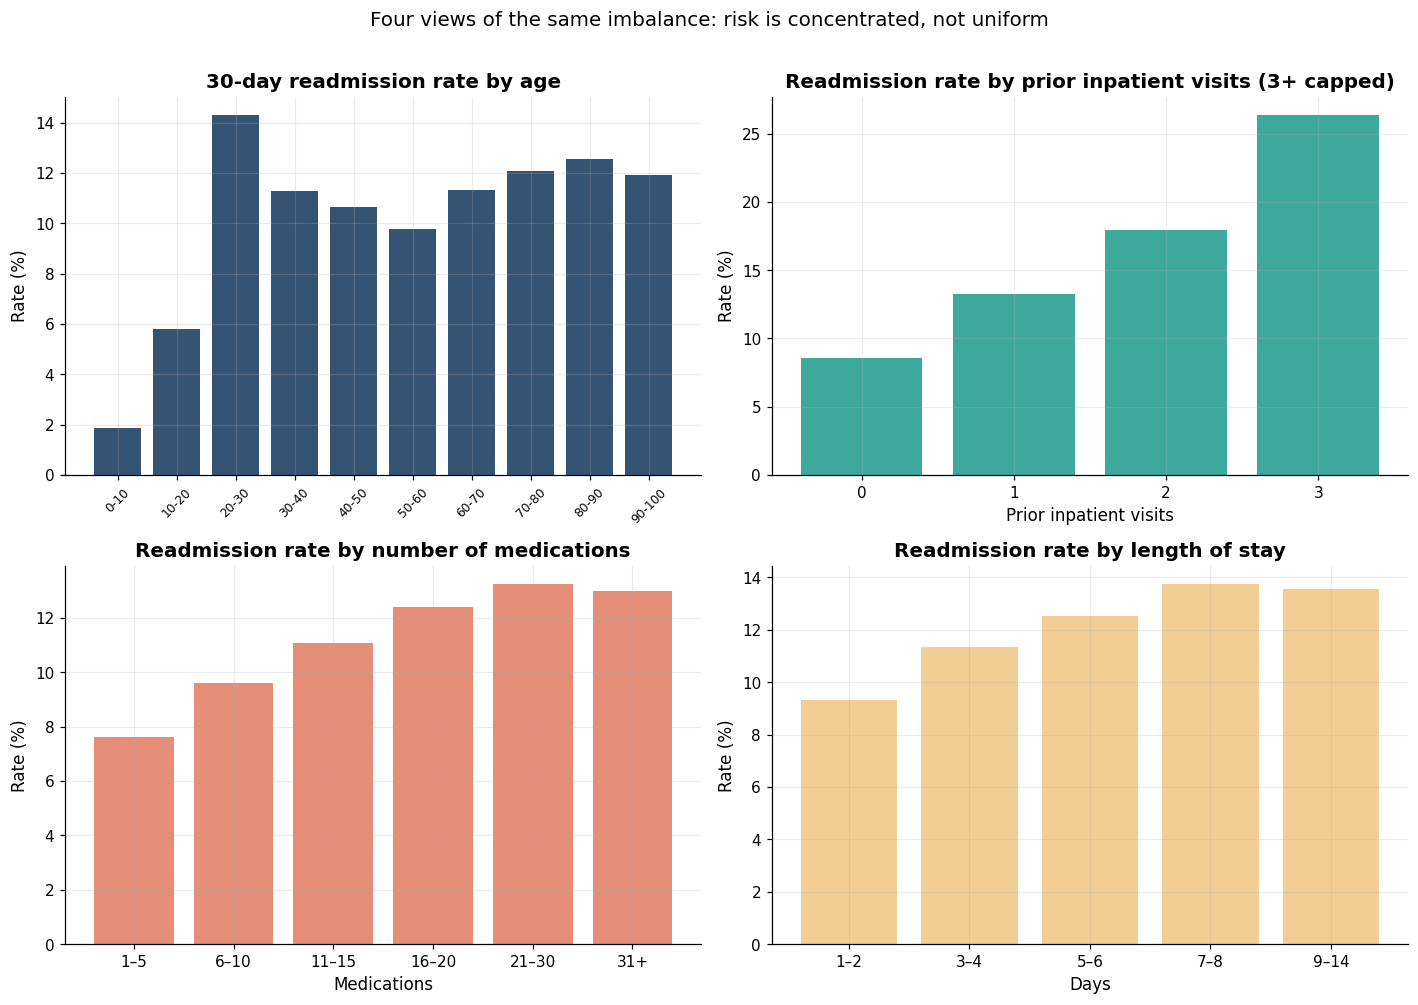

In [7]:
eda = raw[~raw["discharge_disposition_id"].isin(EXCLUDE_DISCHARGE)].copy()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Age
age_order = [f"[{i}-{i+10})" for i in range(0, 100, 10)]
age_rate = (
    eda[eda["age"].isin(age_order)]
    .groupby("age")["readmit_30"].agg(["mean", "size"])
    .reindex(age_order)
)
axes[0, 0].bar(range(len(age_rate)), age_rate["mean"] * 100, color=NAVY, alpha=0.85)
axes[0, 0].set_xticks(range(len(age_rate)))
axes[0, 0].set_xticklabels([a.replace("[", "").replace(")", "") for a in age_rate.index],
                           rotation=45, fontsize=8)
axes[0, 0].set_title("30-day readmission rate by age")
axes[0, 0].set_ylabel("Rate (%)")

# Prior inpatient visits (capped for readability)
prior = eda.copy()
prior["prior_bin"] = prior["number_inpatient"].clip(upper=3).astype(int)
prior_rate = prior.groupby("prior_bin")["readmit_30"].agg(["mean", "size"])
axes[0, 1].bar(prior_rate.index.astype(str), prior_rate["mean"] * 100, color=TEAL, alpha=0.85)
axes[0, 1].set_title("Readmission rate by prior inpatient visits (3+ capped)")
axes[0, 1].set_ylabel("Rate (%)")
axes[0, 1].set_xlabel("Prior inpatient visits")

# Medications
med = eda.copy()
med["med_bin"] = pd.cut(med["num_medications"], bins=[0, 5, 10, 15, 20, 30, 100],
                        labels=["1–5", "6–10", "11–15", "16–20", "21–30", "31+"])
med_rate = med.groupby("med_bin", observed=True)["readmit_30"].agg(["mean", "size"])
axes[1, 0].bar(med_rate.index.astype(str), med_rate["mean"] * 100, color=ORANGE, alpha=0.85)
axes[1, 0].set_title("Readmission rate by number of medications")
axes[1, 0].set_ylabel("Rate (%)")
axes[1, 0].set_xlabel("Medications")

# Time in hospital
stay = eda.copy()
stay["stay_bin"] = pd.cut(stay["time_in_hospital"], bins=[0, 2, 4, 6, 8, 14],
                          labels=["1–2", "3–4", "5–6", "7–8", "9–14"])
stay_rate = stay.groupby("stay_bin", observed=True)["readmit_30"].agg(["mean", "size"])
axes[1, 1].bar(stay_rate.index.astype(str), stay_rate["mean"] * 100, color=GOLD, alpha=0.95)
axes[1, 1].set_title("Readmission rate by length of stay")
axes[1, 1].set_ylabel("Rate (%)")
axes[1, 1].set_xlabel("Days")

fig.suptitle("Four views of the same imbalance: risk is concentrated, not uniform", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

The patterns are clear and clinically plausible:

- **Prior inpatient visits** produce the steepest gradient. Patients with zero prior visits have a
  readmission rate near 8%; one prior visit is about 13%, two is about 18%, and three or more is
  about 26%. A history of admission is a strong signal of future admission.
- **Age** is not a simple upward line. Rates are very low for children, jump to about 14% in the
  20–30 bracket, sit around 10–12% through midlife, and rise again to about 12.5% at 80–90. The
  20–30 peak is notable and probably reflects a different case mix (e.g. acute presentations) rather
  than a pure age effect. I would not over-interpret it without clinical input.
- **Medications** and **length of stay** rise with risk, but less steeply and with more noise. They
  are correlated with severity and with each other.

These are exactly the features the model should pick up. If it did not, I would suspect a bug in the
preprocessing.

## 5. Models and metrics

### 5.1 The accuracy trap

The positive rate is 11.2% in the test set. A model that predicts "no readmission" for every patient
gets **88.8% accuracy** and catches **zero** readmissions. Accuracy is therefore not a useful
headline metric here. I report:

- **Recall** — of the patients who were readmitted, what share did the model flag?
- **Precision** — of the patients the model flagged, what share were actually readmitted?
- **F1** — the harmonic mean of precision and recall; useful when both matter.
- **ROC-AUC** — the probability that a random positive is ranked above a random negative. It is
  threshold-independent but can look good when the positive class is rare.
- **PR-AUC / average precision** — the area under the precision-recall curve. It is more informative
  than ROC-AUC when positives are rare, because it focuses on the positive class.

### 5.2 The two models

- **Logistic regression** is the interpretable baseline: a linear model on the log-odds. It gives
  coefficients I can read as odds ratios and it is easy to deploy. I fit it twice: once unweighted
  (the default) and once with `class_weight="balanced"`.
- **Decision tree** is a non-linear, rule-based model. It can capture thresholds and interactions
  (e.g. "age > 70 and prior visits ≥ 2") without me specifying them. I limit depth to 5 to avoid
  memorising the training set.

`class_weight="balanced"` re-weights the loss so that the minority class counts more. It changes the
model's implicit threshold: the predicted probabilities are no longer calibrated to the original
11% prevalence, so a 0.5 cutoff does not mean "50% chance of readmission" in the population sense.
That is a feature for screening, but it must be explained to anyone using the output.

In [8]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

TARGET = "readmit_30"
DROP = ["patient_nbr", TARGET]

X_train = train_df.drop(columns=DROP)
y_train = train_df[TARGET]
X_test = test_df.drop(columns=DROP)
y_test = test_df[TARGET]

categorical = [c for c in X_train.columns if X_train[c].dtype == "object"]
numeric = [c for c in X_train.columns if c not in categorical]
print(f"{len(numeric)} numeric features, {len(categorical)} categorical features")

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50)),
    ]), categorical),
])


def fit_and_score(name, classifier):
    model = Pipeline([("preprocess", clone(preprocess)), ("classifier", classifier)])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    }, model


log_unweighted, model_unweighted = fit_and_score(
    "Logistic (unweighted)",
    LogisticRegression(max_iter=3000),
)
log_balanced, model_balanced = fit_and_score(
    "Logistic (balanced)",
    LogisticRegression(max_iter=3000, class_weight="balanced"),
)
tree5, model_tree = fit_and_score(
    "Decision tree (depth 5)",
    DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=42
    ),
)

results = pd.DataFrame([log_unweighted, log_balanced, tree5]).set_index("model")
results.round(3)

9 numeric features, 35 categorical features


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
Logistic (unweighted),0.888,0.491,0.025,0.047,0.665,0.219
Logistic (balanced),0.676,0.182,0.543,0.273,0.667,0.219
Decision tree (depth 5),0.654,0.176,0.566,0.268,0.652,0.199


This table is the core of the notebook, and it tells a consistent story:

- The **unweighted logistic** has 88.8% accuracy and 49.1% precision — but **2.5% recall**. It is
  essentially predicting "no" and occasionally flagging a patient when the linear signal is very
  strong. Its F1 is 0.047, which is close to useless as a screening tool. This is the accuracy trap:
  the headline number looks great because the majority class is easy.
- The **balanced logistic** drops accuracy to 67.6% but raises recall to **54.3%**, with precision
  18.2% and F1 0.273. It catches more than half of the readmitted patients, at the cost of flagging a
  lot of non-readmitted ones.
- The **depth-5 tree** is very similar: recall 56.6%, precision 17.6%, F1 0.268. The extra
  flexibility does not buy a meaningful improvement, which is itself informative: the signal in this
  feature set is mostly additive and low-dimensional.

All three have ROC-AUC around 0.65–0.67, and PR-AUC around 0.20–0.22 against a base rate of 0.112.
That is roughly a 2× lift over random ranking. It is not a strong model, but it is not nothing.

### 5.3 Confusion matrices

A single precision/recall pair hides the raw counts. With only ~2,200 positives in the test set, a
few dozen false negatives matter. I show the confusion matrix for each model at the 0.5 threshold.

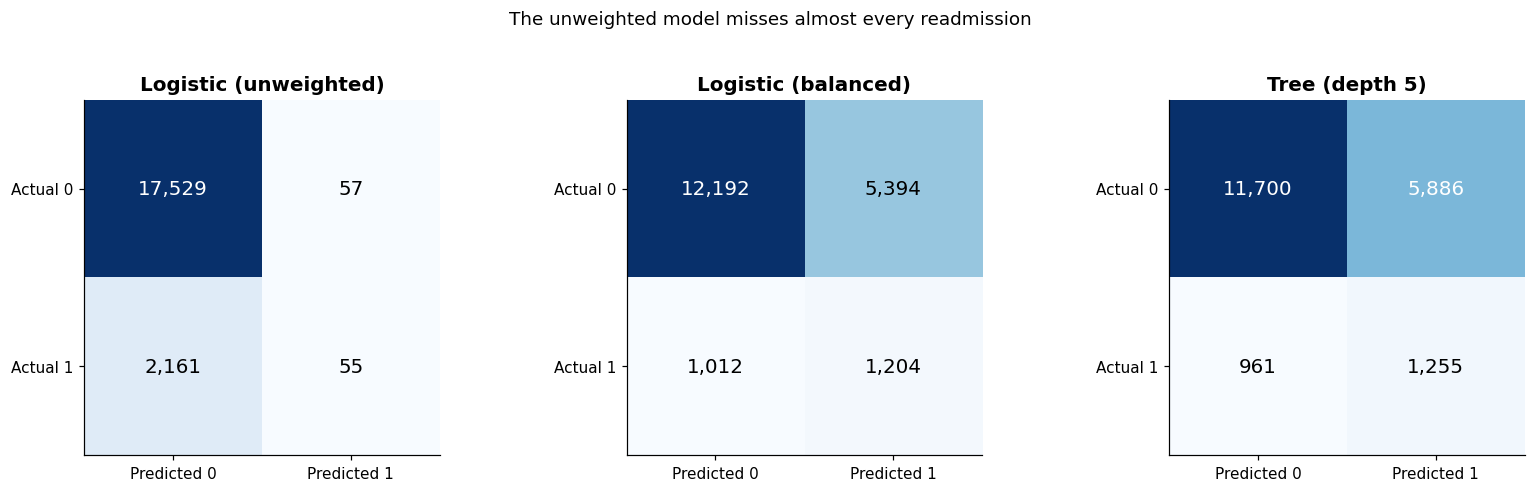

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

for ax, (name, model) in zip(
    axes,
    [("Logistic (unweighted)", model_unweighted),
     ("Logistic (balanced)", model_balanced),
     ("Tree (depth 5)", model_tree)],
):
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    im = ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted 0", "Predicted 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual 0", "Actual 1"])
    ax.set_title(name)
    ax.grid(False)

fig.suptitle("The unweighted model misses almost every readmission", y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

The unweighted matrix has a huge block of true negatives and a tiny number of true positives. It
looks "accurate" because the largest cell is correct. The balanced model shifts predictions into the
positive column: many more true positives, but also many more false positives. There is no free
lunch; the question is which error the programme can tolerate.

### 5.4 Choosing a threshold

The default 0.5 cutoff is arbitrary. A hospital with capacity to follow up, say, 20% of discharges
can lower the threshold and catch more readmissions; a hospital that can only call the top 5% should
raise it. I show the precision/recall trade-off for the balanced logistic model across thresholds.

The key point is that the model outputs a **ranking**; the threshold turns the ranking into a
decision. The right threshold is a business decision, not a statistical one.

In [10]:
proba = model_balanced.predict_proba(X_test)[:, 1]
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
rows = []
for threshold in thresholds:
    pred = (proba >= threshold).astype(int)
    rows.append({
        "threshold": threshold,
        "flagged_share": pred.mean(),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    })
threshold_table = pd.DataFrame(rows).set_index("threshold")
threshold_table.round(3)

,flagged_share,precision,recall,f1
threshold,,,,
0.300,0.952,0.116,0.987,0.208
0.400,0.649,0.140,0.813,0.239
0.500,0.333,0.182,0.543,0.273
0.600,0.150,0.232,0.311,0.266
0.700,0.064,0.301,0.172,0.219


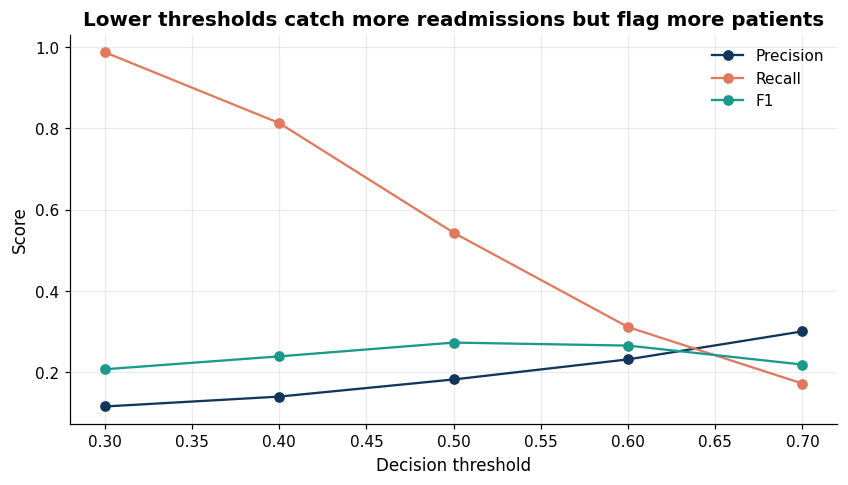

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(threshold_table.index, threshold_table["precision"], marker="o", color=NAVY, label="Precision")
ax.plot(threshold_table.index, threshold_table["recall"], marker="o", color=ORANGE, label="Recall")
ax.plot(threshold_table.index, threshold_table["f1"], marker="o", color=TEAL, label="F1")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Lower thresholds catch more readmissions but flag more patients")
ax.legend(frameon=False)
plt.show()

At a threshold of 0.3, the model catches **98.7%** of readmissions but flags about 95% of all
patients — operationally useless. At 0.7, it flags a much smaller group but catches only 17.2% of
readmissions. The 0.5 point (54.3% recall, 18.2% precision, F1 0.273) is a reasonable default, but it flags a
third of all patients — so it is only useful if the programme has capacity for that many reviews.

A useful way to choose is to attach costs. If a missed readmission costs the hospital far more than
a follow-up call, a lower threshold is justified. If the programme has fixed capacity, pick the
threshold that fills that capacity and read off the expected recall. I do not have cost data here, so
I present the curve rather than pretending there is one correct cutoff.

### 5.5 ROC and precision-recall curves

ROC curves plot true-positive rate against false-positive rate; PR curves plot precision against
recall. With a rare positive class, the PR curve is the more honest summary: a model can have a
respectable ROC-AUC while its precision at any useful recall is low.

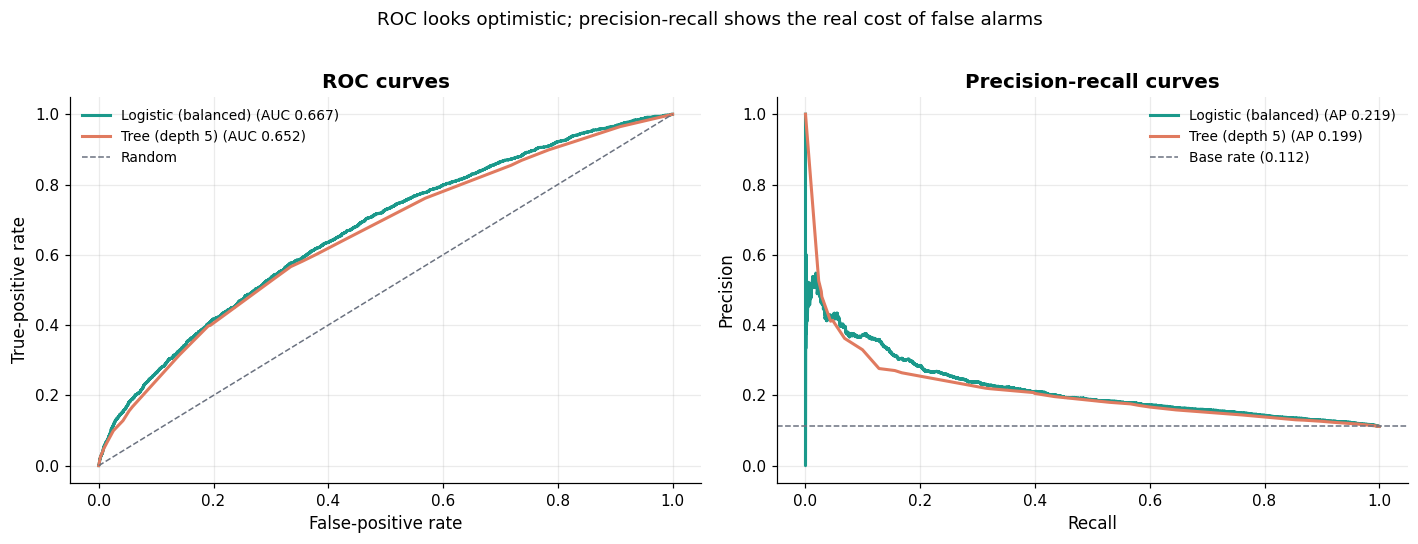

In [12]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for name, model, color in [
    ("Logistic (balanced)", model_balanced, TEAL),
    ("Tree (depth 5)", model_tree, ORANGE),
]:
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=color, lw=2,
                 label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(recall, precision, color=color, lw=2,
                 label=f"{name} (AP {average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1, label="Random")
axes[0].set_xlabel("False-positive rate")
axes[0].set_ylabel("True-positive rate")
axes[0].set_title("ROC curves")
axes[0].legend(frameon=False, fontsize=9)

axes[1].axhline(y_test.mean(), color=GRAY, ls="--", lw=1, label=f"Base rate ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves")
axes[1].legend(frameon=False, fontsize=9)

fig.suptitle("ROC looks optimistic; precision-recall shows the real cost of false alarms", y=1.02)
plt.tight_layout()
plt.show()

The ROC curves sit above the diagonal, but the PR curves show why the task is hard: at 50% recall,
precision is around 20%. In a ward of 100 patients, a 20% precision means four out of five patients
flagged for follow-up would not have been readmitted. That may still be acceptable if the
intervention is cheap and the cost of missing a readmission is high, but it is the number a clinical
team needs to see.

### 5.6 What the model learned

For the logistic model, the coefficients are on the log-odds scale. Exponentiating gives an odds
ratio: `exp(0.364) = 1.44` means each additional prior inpatient visit is associated with about 44%
higher odds of 30-day readmission, holding the other features fixed.

These are associations in an observational dataset, not causal effects. A patient with more prior
visits is sicker in ways the model does not measure, so the coefficient is partly capturing
unobserved severity.

In [13]:
coefs = pd.Series(
    model_balanced.named_steps["classifier"].coef_[0],
    index=model_balanced.named_steps["preprocess"].get_feature_names_out(),
)
numeric_coefs = coefs[[f"num__{c}" for c in numeric]].copy()
numeric_coefs.index = [c.replace("num__", "") for c in numeric_coefs.index]
numeric_table = pd.DataFrame({
    "coefficient (log-odds)": numeric_coefs,
    "odds ratio": np.exp(numeric_coefs),
}).sort_values("coefficient (log-odds)", ascending=False)
numeric_table.round(3)

,coefficient (log-odds),odds ratio
number_inpatient,0.364,1.439
number_diagnoses,0.098,1.103
number_emergency,0.078,1.081
age_num,0.057,1.059
num_medications,0.042,1.043
num_lab_procedures,0.024,1.024
time_in_hospital,0.023,1.023
number_outpatient,-0.003,0.997
num_procedures,-0.048,0.953


`number_inpatient` dominates with a coefficient of **0.364** (odds ratio **1.44** per prior
admission). `number_diagnoses` and `number_emergency` are next, followed by `age_num` and
`num_medications`. `number_outpatient` is essentially zero once the other utilisation variables
are included.

The administrative discharge codes also carry signal, but their coefficients are harder to interpret
because they are one-hot categories with a reference level. Some rare codes have large coefficients
estimated from few patients; I would not build a clinical story around them without checking the
counts. This is a general hazard with high-cardinality categorical features: the model can learn a
rare code as a proxy for something unobserved.

### 5.7 Tree structure and feature importance

A depth-5 tree is small enough to inspect. Its feature importances are not causal, but they show
which variables the tree used to split the population. If the tree leans on a different set of
features than the logistic model, that is a sign the two models are capturing different structure.

In [14]:
tree_model = model_tree.named_steps["classifier"]
tree_features = model_tree.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(tree_model.feature_importances_, index=tree_features)
importance = importance[importance > 0].sort_values(ascending=False).head(12)
importance.index = [i.replace("num__", "").replace("cat__", "").replace("_", " ")[:46]
                   for i in importance.index]
importance.to_frame("importance").round(3)

,importance
number inpatient,0.594
discharge disposition id 1,0.196
discharge disposition id 22,0.064
number diagnoses,0.031
time in hospital,0.019
discharge disposition id 3,0.015
discharge disposition id 5,0.013
age num,0.009
diag 1 Circulatory,0.009
discharge disposition id 2,0.008


The tree's top features overlap with the logistic model's: prior inpatient visits, discharge
disposition, number of diagnoses, and age. That consistency is reassuring. The tree adds thresholds
and interactions, but the depth-5 version does not improve the holdout metrics much — the signal is
mostly linear and the dataset is noisy.

## 6. Evaluation in plain language

**ROC-AUC 0.667.** If I pick one readmitted patient and one non-readmitted patient at random, the
model ranks the readmitted one higher about two-thirds of the time. That is better than a coin flip,
but far from a reliable triage tool.

**PR-AUC 0.219 vs a base rate of 0.112.** The model roughly doubles the precision you would get by
flagging patients at random. In a population with 11% readmissions, a random flag is right about 11%
of the time; the model's flags are right about 22% of the time.

**Recall 54.3% at threshold 0.5.** The model catches about half of the patients who will be
readmitted. The other half are missed. If the programme's goal is "do not miss anyone", this is not
good enough; if the goal is "use limited capacity on the highest-risk patients", it can be useful.

**Precision 18.2%.** Four out of five flagged patients would not have been readmitted. Whether that
is acceptable depends on the intervention: a cheap phone call is different from a home visit.

**Accuracy 88.8% for the unweighted model is a trap.** It is the accuracy of a model that mostly
predicts "no". Reporting it without recall would misrepresent the model's usefulness.

**What I would tell a stakeholder:** "We can rank patients by risk better than chance, and we can
tune the flag rate to your capacity. The model is not accurate enough to make automatic decisions.
Use it to prioritise a human review, and track the false-positive cost."

## 7. Limitations and next steps

**Observational, not causal.** The coefficients describe associations. A patient with more prior
admissions is sicker in ways the data does not capture. Do not read the odds ratios as "one more
admission causes a 44% higher risk".

**Label simplification.** Collapsing `>30` into the negative class treats a readmission on day 45
the same as no readmission. A survival or competing-risks model would use the timing information
properly.

**Administrative data only.** The dataset has no lab values, vital signs, medication adherence,
housing status, social support, or discharge destination beyond a code. Those are likely the
strongest predictors of whether a patient actually returns.

**Old data.** 1999–2008. Clinical practice, coding, and readmission penalties have changed. The model
is a methodological exercise, not a current clinical tool.

**No calibration.** `class_weight="balanced"` changes the meaning of the predicted probability. The
scores are useful for ranking, but they are not calibrated risks. A reliability curve and Platt/isotonic
calibration would be needed before quoting "this patient has a 30% risk".

**Fairness.** Race, age, and gender are in the model, along with administrative admission and
discharge codes. Insurance (`payer_code`) was dropped because it is 39.6% missing; dropping it does
not remove the possibility of proxy bias. A model can encode
structural inequities in access and care. Any deployment would need subgroup performance analysis and
a clear policy on which features are acceptable.

**No temporal validation.** The group split prevents patient leakage, but it is still a random split
within the same period. A time-based split (train on earlier years, test on later ones) would be a
harder and more realistic test of deployment.

**Threshold is a policy choice.** I show the trade-off instead of hiding it. In a real system, the
threshold would be set with the care team, based on capacity and the relative cost of a missed
readmission versus a false alarm.

**Next steps:** (1) calibrate the probabilities; (2) add lab and vital-sign features if available;
(3) try gradient boosting and compare with the logistic baseline; (4) evaluate subgroup performance;
(5) run a time-based validation; (6) cost-sensitive threshold optimisation with real intervention
costs.

## 8. References

- UCI Machine Learning Repository, *Diabetes 130-US Hospitals for Years 1999–2008*:
  https://archive.ics.uci.edu/dataset/296/diabetes-130-us-hospitals-for-years-1999-2008
- Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of
  70,000 Clinical Database Patient Records.* BioMed Research International.
- scikit-learn, *Classification metrics*:
  https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
- scikit-learn, *GroupShuffleSplit*:
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html
- CMS, *Hospital Readmissions Reduction Program*: https://www.cms.gov/medicare/payment/prospective-payment-systems/acute-inpatient-pps/hospital-readmissions-reduction-program-hrrp

---

*Reproduce: `pip install -r ../requirements.txt`, place `diabetic_data.csv` in `data/`, then run the
notebook top to bottom. Runtime is about 30–60 seconds on a laptop.*